<a href="https://colab.research.google.com/github/bibhutibsahu/Python-Coding-Interview/blob/main/Kailedofin_tech_round.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kailedofin

In [ ]:
import pandas as pd

data = {
    "customer": ["A", "A", "A", "A", "A", "B", "B", "B", "B", "B", "C", "C", "C", "C", "C", "D", "D", "D", "D", "D"],
    "transaction_id": [101, 102, 103, 104, 105, 201, 202, 203, 204, 205, 301, 302, 303, 304, 305, 401, 402, 403, 404, 405],
    "transaction_date": ["2026-01-05", "2026-01-20", "2026-02-15", "2026-03-10", "2026-03-25", "2026-01-10", "2026-01-25", "2026-02-20", "2026-03-05", "2026-03-28", "2026-01-15", "2026-02-05", "2026-02-25", "2026-03-15", "2026-03-30", "2026-01-08", "2026-01-30", "2026-02-18", "2026-03-12", "2026-03-27"],
    "product": ["Laptop", "Phone", "Tablet", "Laptop", "Phone", "Phone", "Laptop", "Tablet", "Phone", "Laptop", "Laptop", "Tablet", "Phone", "Laptop", "Tablet", "Tablet", "Phone", "Laptop", "Tablet", "Laptop"],
    "amount": [80000, 50000, 30000, 80000, 40000, 60000, 90000, 20000, 60000, 50000, 100000, 40000, 40000, 70000, 35000, 30000, 50000, 90000, 30000, 70000],
    "status": ["completed", "completed", "cancelled", "completed", "completed", "completed", "completed", "completed", "cancelled", "completed", "completed", "completed", "cancelled", "completed", "completed", "completed", "completed", "completed", "completed", "completed"]
}

df = pd.DataFrame(data)

In [ ]:
df

,customer,transaction_id,transaction_date,product,amount,status
0,A,101,2026-01-05,Laptop,80000,completed
1,A,102,2026-01-20,Phone,50000,completed
2,A,103,2026-02-15,Tablet,30000,cancelled
3,A,104,2026-03-10,Laptop,80000,completed
4,A,105,2026-03-25,Phone,40000,completed
5,B,201,2026-01-10,Phone,60000,completed
6,B,202,2026-01-25,Laptop,90000,completed
7,B,203,2026-02-20,Tablet,20000,completed
8,B,204,2026-03-05,Phone,60000,cancelled
9,B,205,2026-03-28,Laptop,50000,completed


In [ ]:
import numpy as np

In [ ]:
import duckdb

# We alias the 'df' DataFrame as 'transaction' inside the SQL query
query = """
with result as (
    select customer, sum(amount) as total_amt
    from df
    where status = 'completed'
    group by 1
)
select t.*, t.amount * 100.0 / r.total_amt as pct_txn
from df t
join result r on t.customer = r.customer
where t.status = 'completed';
"""

duckdb.query(query).to_df()

,customer,transaction_id,transaction_date,product,amount,status,pct_txn
0,A,101,2026-01-05,Laptop,80000,completed,32.000000
1,A,102,2026-01-20,Phone,50000,completed,20.000000
2,A,104,2026-03-10,Laptop,80000,completed,32.000000
3,A,105,2026-03-25,Phone,40000,completed,16.000000
4,B,201,2026-01-10,Phone,60000,completed,27.272727
5,B,202,2026-01-25,Laptop,90000,completed,40.909091
6,B,203,2026-02-20,Tablet,20000,completed,9.090909
7,B,205,2026-03-28,Laptop,50000,completed,22.727273
8,C,301,2026-01-15,Laptop,100000,completed,40.816327
9,C,302,2026-02-05,Tablet,40000,completed,16.326531


In [ ]:
# Pure pandas equivalent of the SQL logic
# 1. Filter for completed transactions
completed_df = df[df['status'] == 'completed'].copy()

# 2. Calculate the total completed amount per customer
customer_totals = completed_df.groupby('customer')['amount'].transform('sum')

# 3. Calculate percentage contribution for each transaction
completed_df['pct_txn'] = (completed_df['amount'] * 100.0) / customer_totals

display(completed_df)

,customer,transaction_id,transaction_date,product,amount,status,pct_txn
0,A,101,2026-01-05,Laptop,80000,completed,32.000000
1,A,102,2026-01-20,Phone,50000,completed,20.000000
3,A,104,2026-03-10,Laptop,80000,completed,32.000000
4,A,105,2026-03-25,Phone,40000,completed,16.000000
5,B,201,2026-01-10,Phone,60000,completed,27.272727
6,B,202,2026-01-25,Laptop,90000,completed,40.909091
7,B,203,2026-02-20,Tablet,20000,completed,9.090909
9,B,205,2026-03-28,Laptop,50000,completed,22.727273
10,C,301,2026-01-15,Laptop,100000,completed,40.816327
11,C,302,2026-02-05,Tablet,40000,completed,16.326531


In [ ]:
l1 = [2, 11, 7, 15]
target = 9

def matching_sum():
    found = False
    for i in range(len(l1)):
        for j in range(i + 1, len(l1)):
            if l1[i] + l1[j] == target:
                print(f"The indexes are: {i}, {j} (values: {l1[i]}, {l1[j]})")
                found = True
    if not found:
        print("No Matching sum available")

matching_sum()

The indexes are: 0, 2 (values: 2, 7)


In [ ]:
# Define a dictionary containing exposure values in Rs Lakh for each customer
exposure = {"C101": 120, "C102": 15, "C103": 340, "C104": 60,
            "C105": 25, "C106": 210, "C107": 10, "C108": 220}   # Rs lakh

# Sort the customer-exposure pairs in descending order based on exposure values (easier approach using dict.get as the key)
items = sorted(exposure.items(), key=lambda item: item[1], reverse=True)

# Calculate the total exposure across all customers
total = sum(exposure.values())

# Initialize a running total to keep track of the cumulative exposure
running = 0

# Initialize an empty list to store the customers who contribute to the top 80%
chosen = []

# Loop through the sorted list of customers and their respective exposure amounts
for cust, amt in items:
  running += amt           # Add current customer's exposure to the running total
  chosen.append(cust)      # Add current customer ID to the list of chosen customers
  if running >= 0.8 * total: # Stop if the cumulative exposure reaches or exceeds 80% of total
    break

# Print the total exposure calculated
print("total exposure: ", total)

# Print the number of customers and list of customers that make up at least 80% of the exposure
print("customers covering 80% : ", len(chosen), chosen)

total exposure:  1000
customers covering 80% :  4 ['C103', 'C108', 'C106', 'C101']


In [ ]:
#solving the list recursion problem

batches = ["INV001", ["INV002", "INV003", ["INV004", ["INV005"]]], [], "INV006", [["INV007"]]]

flat = []
max_depth = 0
stack = [(batches,0,1)]
while stack:
  lst , pos, depth = stack.pop()
  if pos == len(lst):
    continue
  max_depth = max(max_depth, depth)
  item = lst[pos]
  stack.append((lst,pos+1,depth))
  if isinstance(item,list):
    stack.append((item,0,depth+1))
  else:
    flat.append(item)

  print(flat)
  print("max_depth", max_depth)

['INV001']
max_depth 1
['INV001']
max_depth 1
['INV001', 'INV002']
max_depth 2
['INV001', 'INV002', 'INV003']
max_depth 2
['INV001', 'INV002', 'INV003']
max_depth 2
['INV001', 'INV002', 'INV003', 'INV004']
max_depth 3
['INV001', 'INV002', 'INV003', 'INV004']
max_depth 3
['INV001', 'INV002', 'INV003', 'INV004', 'INV005']
max_depth 4
['INV001', 'INV002', 'INV003', 'INV004', 'INV005']
max_depth 4
['INV001', 'INV002', 'INV003', 'INV004', 'INV005', 'INV006']
max_depth 4
['INV001', 'INV002', 'INV003', 'INV004', 'INV005', 'INV006']
max_depth 4
['INV001', 'INV002', 'INV003', 'INV004', 'INV005', 'INV006']
max_depth 4
['INV001', 'INV002', 'INV003', 'INV004', 'INV005', 'INV006', 'INV007']
max_depth 4


In [1]:
data = {
    'customer_id':     [1, 2, 3, 4, 5, 6],
    'predicted_prob':  [0.90, 0.70, 0.40, 0.65, 0.30, 0.61],
    'actual_churned':  [1, 0, 1, 1, 1, 0]
}
#Compute precision and recall at a threshold of 0.6 (predicted positive if predicted_prob >= 0.6), without using sklearn's built-in functions.

In [2]:
import pandas as pd
df = pd.DataFrame(data)

In [3]:
# Threshold for predicting churn
threshold = 0.6

# Classify as predicted positive (1) if predicted_prob >= threshold, else negative (0)
predicted_positive = df['predicted_prob'] >= threshold
actual_positive = df['actual_churned'] == 1

# True Positives (TP): Predicted Positive and Actual Positive
tp = (predicted_positive & actual_positive).sum()

# False Positives (FP): Predicted Positive and Actual Negative
fp = (predicted_positive & ~actual_positive).sum()

# False Negatives (FN): Predicted Negative and Actual Positive
fn = (~predicted_positive & actual_positive).sum()

# Compute Precision and Recall
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

print(f"True Positives (TP): {tp}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

True Positives (TP): 2
False Positives (FP): 2
False Negatives (FN): 2
Precision: 0.5000
Recall: 0.5000


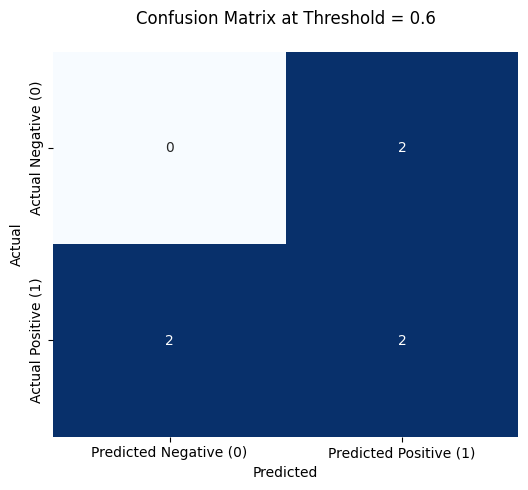

=== Customer Classification Breakdown ===
Customer 1: Prob=0.90, Actual=1, Predicted=1 -> True Positive (TP) - Correctly Predicted Churn
Customer 2: Prob=0.70, Actual=0, Predicted=1 -> False Positive (FP) - Incorrectly Predicted Churn
Customer 3: Prob=0.40, Actual=1, Predicted=0 -> False Negative (FN) - Missed Churn
Customer 4: Prob=0.65, Actual=1, Predicted=1 -> True Positive (TP) - Correctly Predicted Churn
Customer 5: Prob=0.30, Actual=1, Predicted=0 -> False Negative (FN) - Missed Churn
Customer 6: Prob=0.61, Actual=0, Predicted=1 -> False Positive (FP) - Incorrectly Predicted Churn


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate True Negatives (TN) to complete the matrix
# True Negatives: Predicted Negative and Actual Negative
tn = (~predicted_positive & ~actual_positive).sum()

# Construct the confusion matrix array
# Format: [[TN, FP], [FN, TP]]
cm = np.array([[tn, fp], [fn, tp]])

# Plot the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted Negative (0)", "Predicted Positive (1)"],
            yticklabels=["Actual Negative (0)", "Actual Positive (1)"])
plt.ylabel("Actual")
plt.xlabel("Predicted")

# Adjust top margin so title is fully visible
plt.title("Confusion Matrix at Threshold = 0.6", pad=20)
plt.show()

# Create mapping breakdown for each customer
print("=== Customer Classification Breakdown ===")
for idx, row in df.iterrows():
    cust_id = row['customer_id']
    prob = row['predicted_prob']
    actual = row['actual_churned']
    pred = 1 if prob >= threshold else 0

    if pred == 1 and actual == 1:
        category = "True Positive (TP) - Correctly Predicted Churn"
    elif pred == 1 and actual == 0:
        category = "False Positive (FP) - Incorrectly Predicted Churn"
    elif pred == 0 and actual == 1:
        category = "False Negative (FN) - Missed Churn"
    else:
        category = "True Negative (TN) - Correctly Predicted Non-Churn"

    print(f"Customer {int(cust_id)}: Prob={prob:.2f}, Actual={int(actual)}, Predicted={pred} -> {category}")